<a href="https://colab.research.google.com/github/Yamuna1911/FDP/blob/main/Child_stunting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
victoriahayes_stunting_toddler_dataset_path = kagglehub.dataset_download('victoriahayes/stunting-toddler-dataset')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/victoriahayes/stunting-toddler-dataset/childhood_stunting_dataset.csv


In [ ]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    LabelEncoder, OrdinalEncoder, StandardScaler
)
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import joblib

sns.set_style("whitegrid")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [ ]:
dataset_path = "/kaggle/input/datasets/victoriahayes/stunting-toddler-dataset"

files = []

for ext in ["*.csv", "*.xlsx", "*.xls"]:
    files.extend(
        glob.glob(
            os.path.join(dataset_path, "**", ext),
            recursive=True
        )
    )

if not files:
    raise FileNotFoundError("No dataset file found!")

print("Available files:")
for i, f in enumerate(files):
    print(i, f)

file_path = files[0]

if file_path.endswith(".csv"):
    df = pd.read_csv(file_path)
else:
    df = pd.read_excel(file_path)

print("\nDataset Loaded Successfully")
print("Shape:", df.shape)

display(df.head())

Available files:
0 /kaggle/input/datasets/victoriahayes/stunting-toddler-dataset/childhood_stunting_dataset.csv

Dataset Loaded Successfully
Shape: (2523, 20)


,Child Age,Gender,Birth Length,Birth Weight,Height,Weight,Mother Age,Mother Education,Mother Height,ANC Visits,Exclusive Breastfeeding,Complementary Feeding Start Age,Immunization,Diarrhea Frequency,Drinking Water Source,Sanitation,Economic Level,Residence Type,Deworming Drug Consumption,Stunting Risk
0,17,M,50.6,3.39,81.1,10.18,22.0,High School,158.07,3.0,No,5.0,Incomplete,1,Unprotected,Improved,Middle,Rural,Yes,Low
1,35,F,50.6,3.81,95.5,14.97,22.0,Elementary/Middle School,155.90,4.0,No,5.0,Complete,3,Unprotected,Improved,Middle,Urban,No,Low
2,58,F,43.5,3.01,105.2,16.37,32.0,University,150.80,7.0,Yes,6.0,Complete,0,Unprotected,Improved,High,Urban,Yes,Low
3,45,M,46.9,2.80,101.0,15.62,28.0,University,159.60,4.0,Yes,4.0,Not Immunized,0,Protected,Improved,Middle,Rural,Yes,Low
4,27,F,46.1,4.00,77.0,8.80,26.0,Elementary/Middle School,150.60,3.0,No,2.0,Not Immunized,2,Unprotected,Unimproved,Low,Rural,No,High


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (2523, 20)

Column Names:
['Child Age', 'Gender', 'Birth Length', 'Birth Weight', 'Height', 'Weight', 'Mother Age', 'Mother Education', 'Mother Height', 'ANC Visits', 'Exclusive Breastfeeding', 'Complementary Feeding Start Age', 'Immunization', 'Diarrhea Frequency', 'Drinking Water Source', 'Sanitation', 'Economic Level', 'Residence Type', 'Deworming Drug Consumption', 'Stunting Risk']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2523 entries, 0 to 2522
Data columns (total 20 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Child Age                        2523 non-null   int64  
 1   Gender                           2523 non-null   object 
 2   Birth Length                     2460 non-null   float64
 3   Birth Weight                     2471 non-null   float64
 4   Height                           2523 non-null   float64
 5   Weight                      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Child Age,2523.0,NaN,NaN,NaN,29.488308,17.248526,2.0,14.0,30.0,44.0,59.0
Gender,2523,2,F,1281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Birth Length,2460.0,NaN,NaN,NaN,48.030106,2.502553,38.2,46.4,48.0,49.7,55.3
Birth Weight,2471.0,NaN,NaN,NaN,2.974937,0.467353,1.24,2.66,2.98,3.28,4.37
Height,2523.0,NaN,NaN,NaN,83.682148,15.496317,45.5,72.5,85.8,96.0,117.3
Weight,2523.0,NaN,NaN,NaN,10.723789,3.713201,2.54,8.1,10.94,13.365,21.84
Mother Age,2510.0,NaN,NaN,NaN,28.941434,5.041098,18.0,26.0,29.0,32.0,45.0
Mother Education,2523,4,High School,928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mother Height,2523.0,NaN,NaN,NaN,153.407218,5.759373,136.8,149.6,153.3,157.4,172.6
ANC Visits,2453.0,NaN,NaN,NaN,4.240522,2.176556,0.0,3.0,4.0,6.0,12.0



Missing Values:


Child Age                           0
Gender                              0
Birth Length                       63
Birth Weight                       52
Height                              0
Weight                              0
Mother Age                         13
Mother Education                    0
Mother Height                       0
ANC Visits                         70
Exclusive Breastfeeding             0
Complementary Feeding Start Age    41
Immunization                       14
Diarrhea Frequency                  0
Drinking Water Source              34
Sanitation                         17
Economic Level                      0
Residence Type                      0
Deworming Drug Consumption         15
Stunting Risk                       0
dtype: int64


Duplicate Records: 0


In [ ]:
df.columns = df.columns.str.strip()

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Clean categorical values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Automatically identify target
target_candidates = [
    col for col in df.columns
    if "stunting" in col.lower()
]

if not target_candidates:
    raise ValueError("Stunting target column not found!")

TARGET = target_candidates[0]

print("Target Variable:", TARGET)

# Remove records without target
df = df.dropna(subset=[TARGET]).copy()

print("Cleaned Dataset Shape:", df.shape)

display(df.head())

Target Variable: Stunting Risk
Cleaned Dataset Shape: (2523, 20)


,Child Age,Gender,Birth Length,Birth Weight,Height,Weight,Mother Age,Mother Education,Mother Height,ANC Visits,Exclusive Breastfeeding,Complementary Feeding Start Age,Immunization,Diarrhea Frequency,Drinking Water Source,Sanitation,Economic Level,Residence Type,Deworming Drug Consumption,Stunting Risk
0,17,M,50.6,3.39,81.1,10.18,22.0,High School,158.07,3.0,No,5.0,Incomplete,1,Unprotected,Improved,Middle,Rural,Yes,Low
1,35,F,50.6,3.81,95.5,14.97,22.0,Elementary/Middle School,155.90,4.0,No,5.0,Complete,3,Unprotected,Improved,Middle,Urban,No,Low
2,58,F,43.5,3.01,105.2,16.37,32.0,University,150.80,7.0,Yes,6.0,Complete,0,Unprotected,Improved,High,Urban,Yes,Low
3,45,M,46.9,2.80,101.0,15.62,28.0,University,159.60,4.0,Yes,4.0,Not Immunized,0,Protected,Improved,Middle,Rural,Yes,Low
4,27,F,46.1,4.00,77.0,8.80,26.0,Elementary/Middle School,150.60,3.0,No,2.0,Not Immunized,2,Unprotected,Unimproved,Low,Rural,No,High


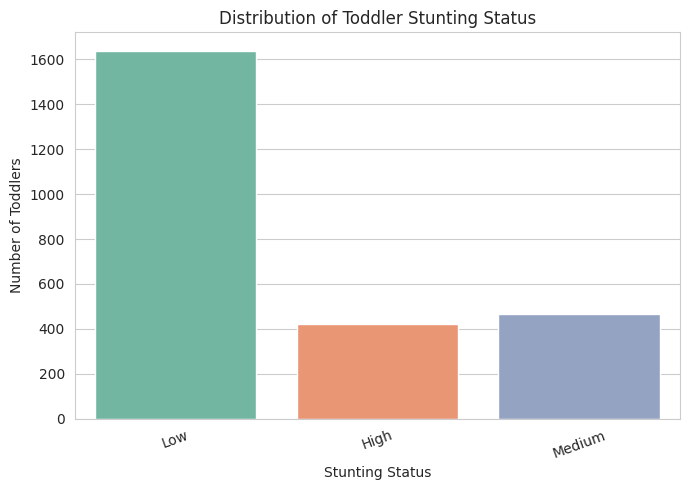

Stunting Risk
Low       1639
Medium     464
High       420
Name: count, dtype: int64

Percentage Distribution:
Stunting Risk
Low       64.962346
Medium    18.390805
High      16.646849
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET,
    hue=TARGET,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Toddler Stunting Status")
plt.xlabel("Stunting Status")
plt.ylabel("Number of Toddlers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(df[TARGET].value_counts())
print("\nPercentage Distribution:")
print(df[TARGET].value_counts(normalize=True) * 100)

,Column,Missing Values,Percentage
0,Child Age,0,0.000000
1,Gender,0,0.000000
2,Birth Length,63,2.497027
3,Birth Weight,52,2.061038
4,Height,0,0.000000
5,Weight,0,0.000000
6,Mother Age,13,0.515260
7,Mother Education,0,0.000000
8,Mother Height,0,0.000000
9,ANC Visits,70,2.774475


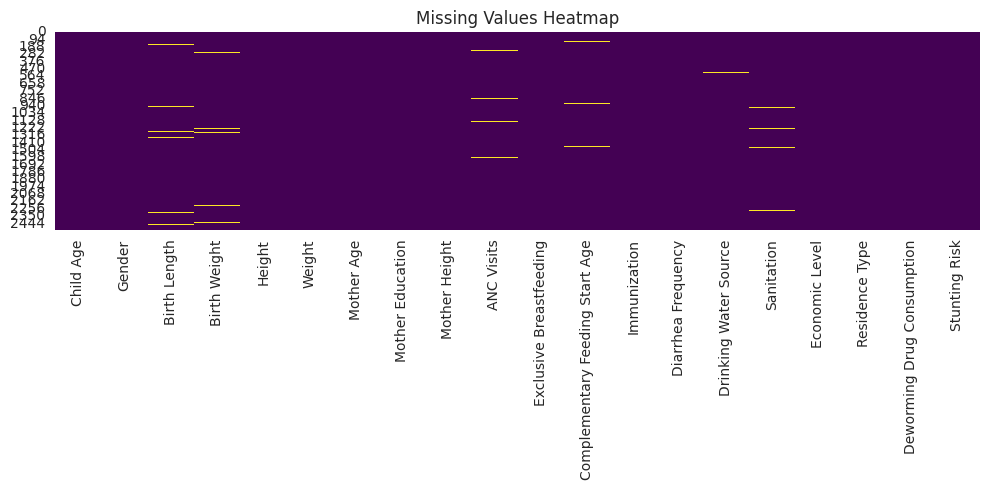

In [ ]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values,
    "Percentage": (missing.values / len(df)) * 100
})

display(missing_df)

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.tight_layout()
plt.show()

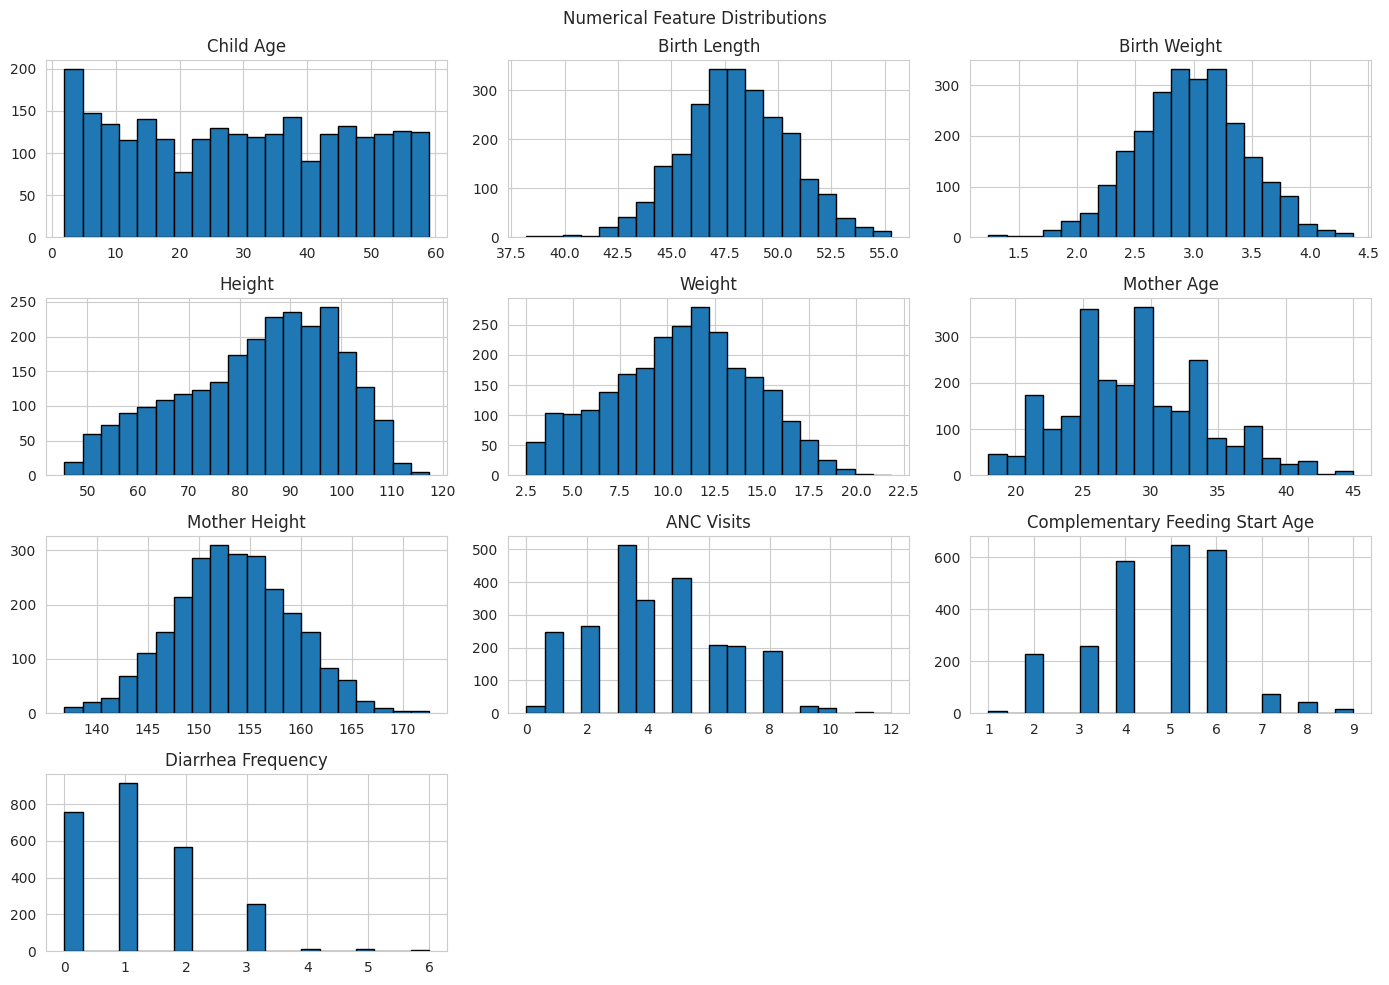

In [ ]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

if numeric_cols:

    df[numeric_cols].hist(
        figsize=(14, 10),
        bins=20,
        edgecolor="black"
    )

    plt.suptitle("Numerical Feature Distributions")
    plt.tight_layout()
    plt.show()

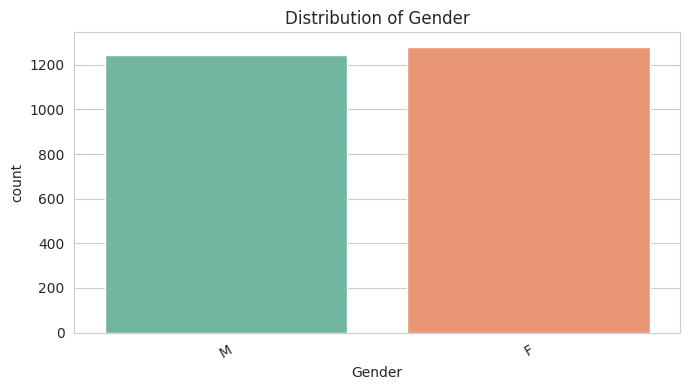

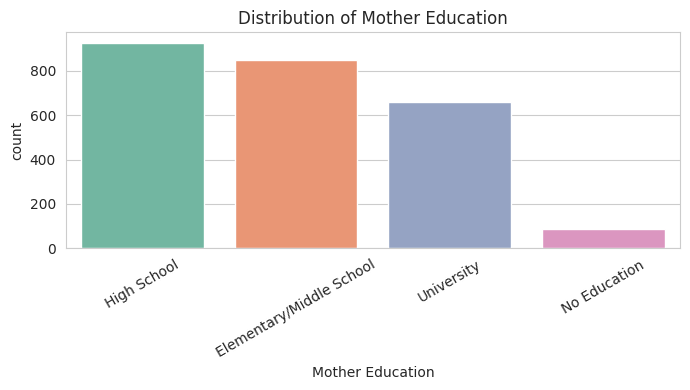

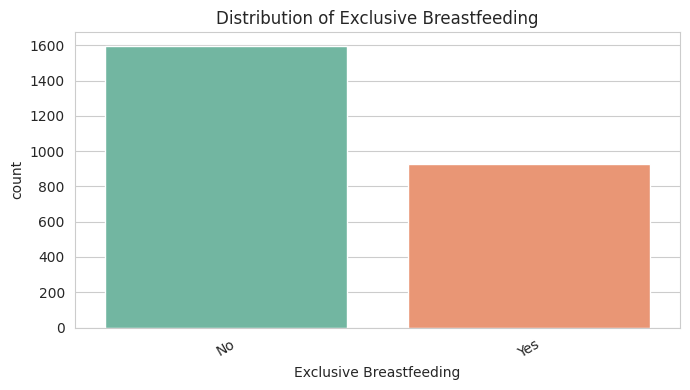

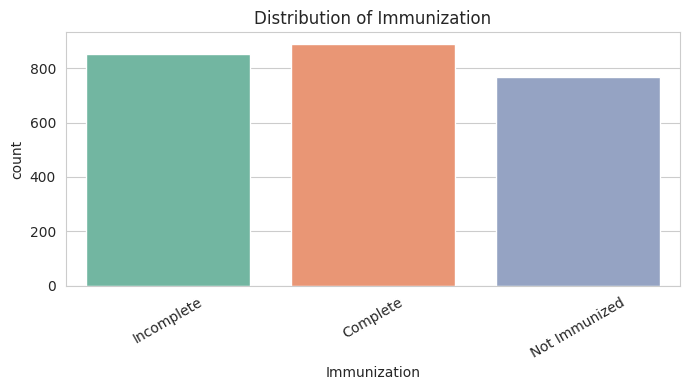

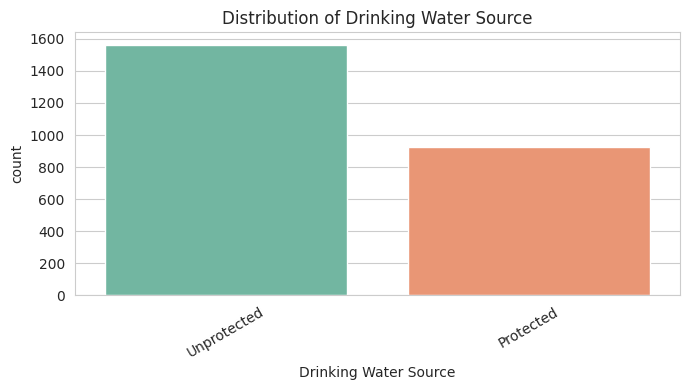

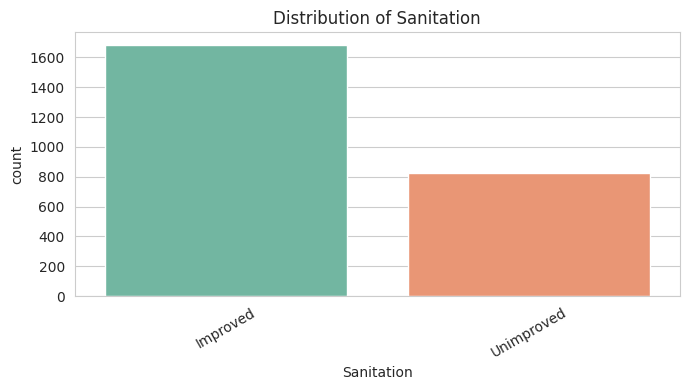

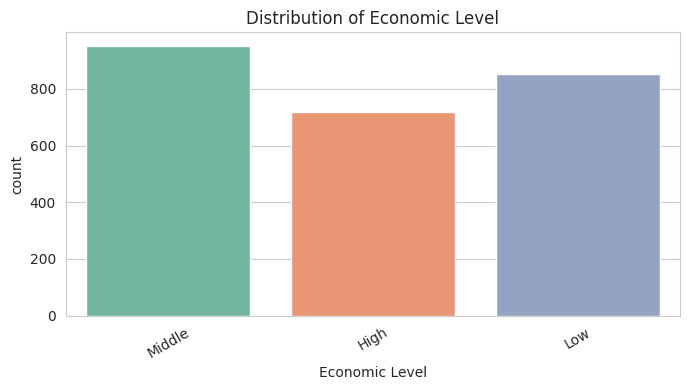

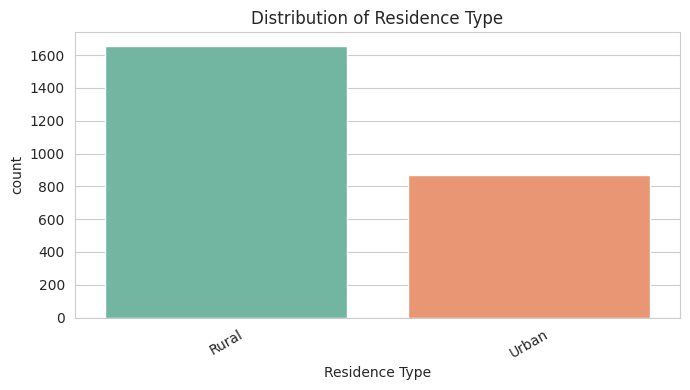

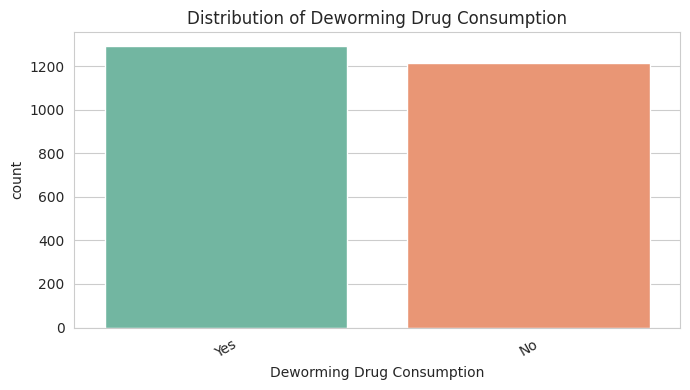

In [ ]:
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in categorical_cols:

    if col == TARGET:
        continue

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        palette="Set2",
        legend=False
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

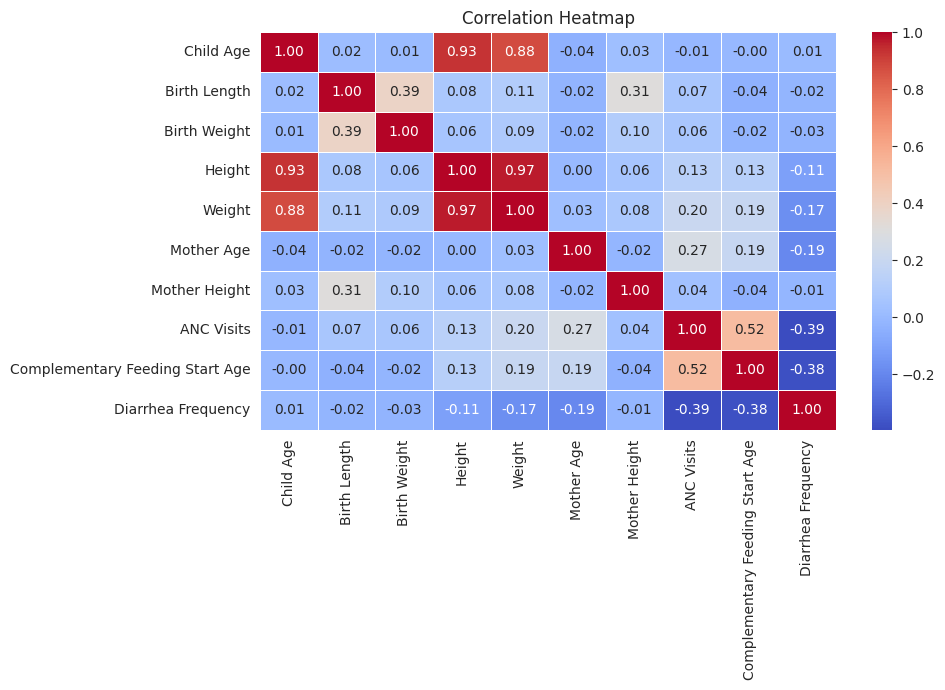

In [ ]:
correlation = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

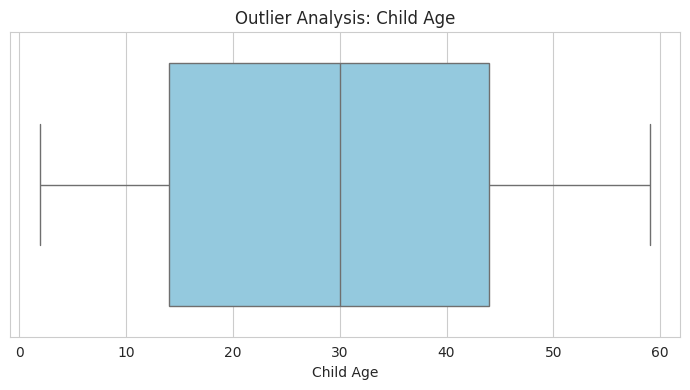

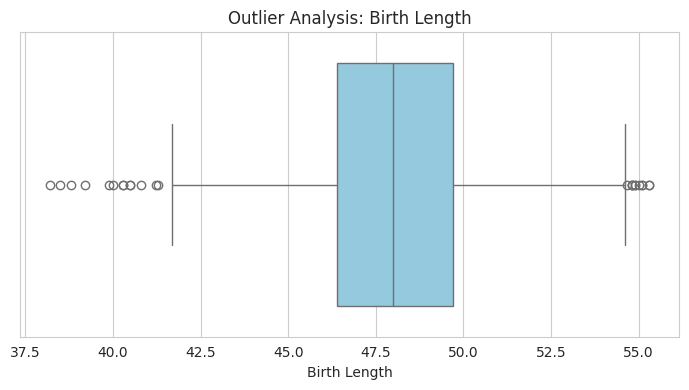

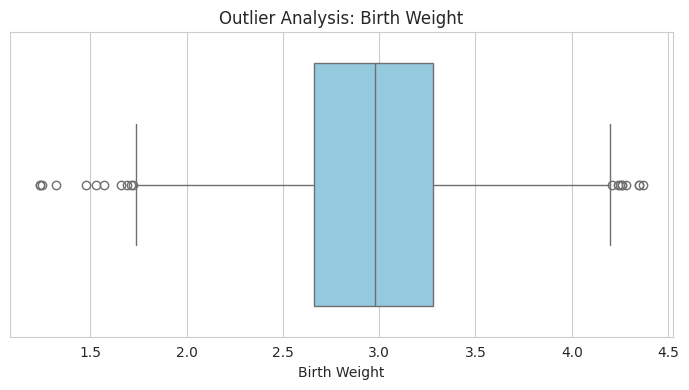

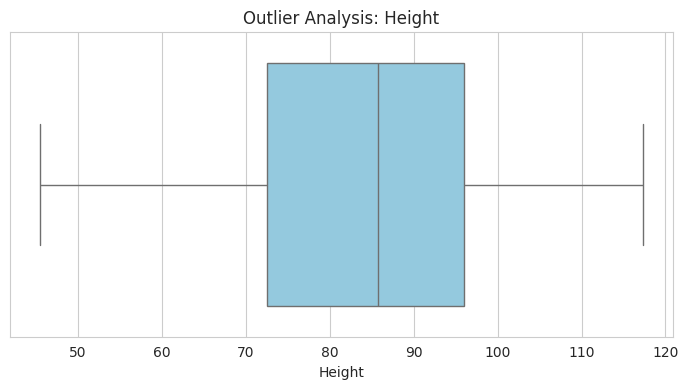

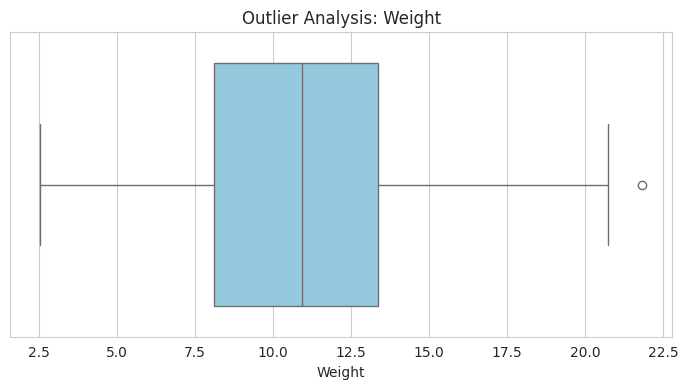

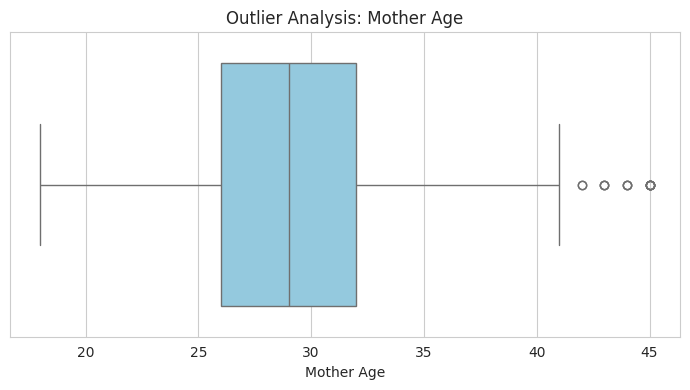

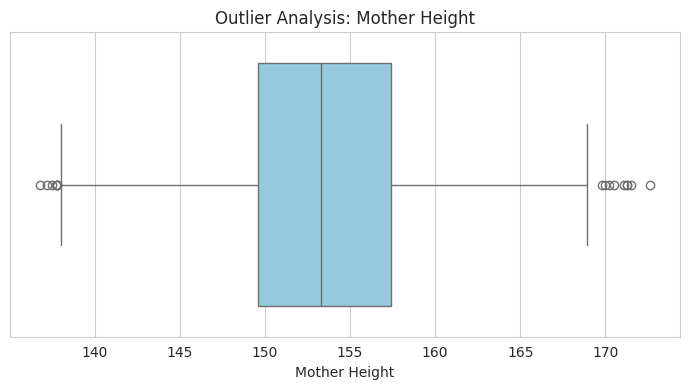

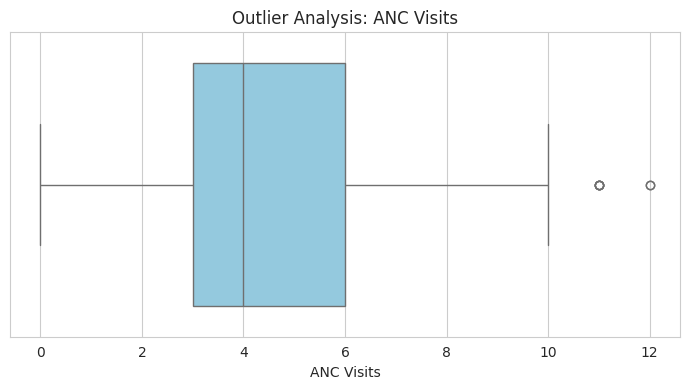

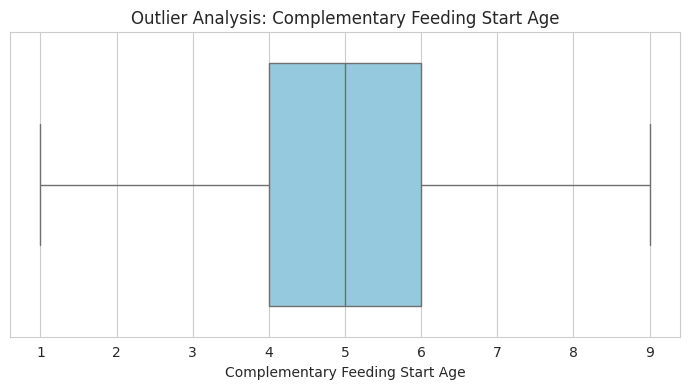

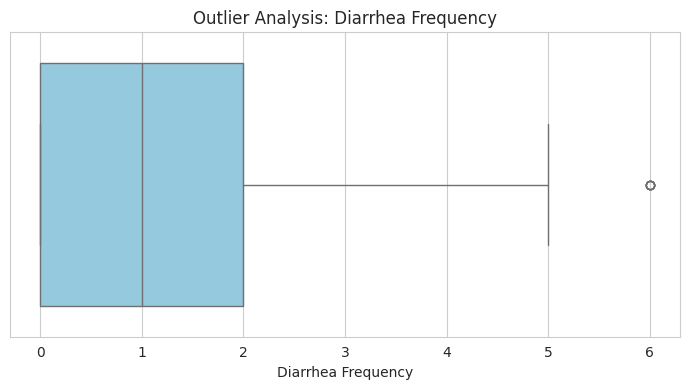

In [ ]:
for col in numeric_cols:

    if col == TARGET:
        continue

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        x=df[col],
        color="skyblue"
    )

    plt.title(f"Outlier Analysis: {col}")
    plt.tight_layout()
    plt.show()

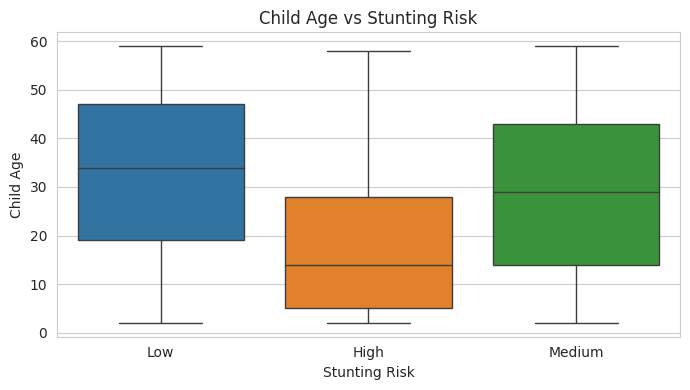

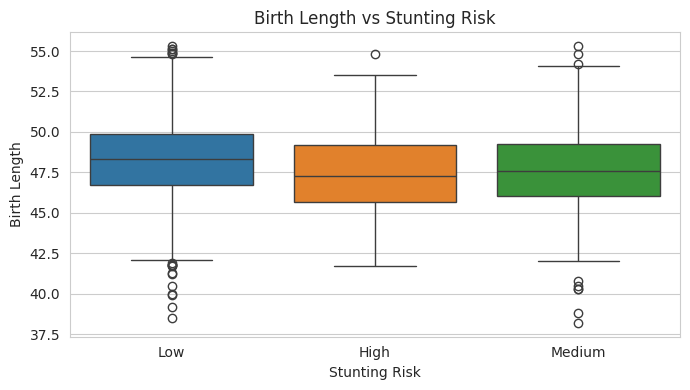

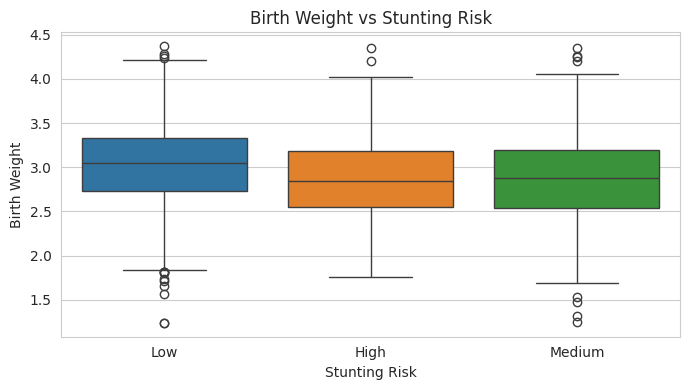

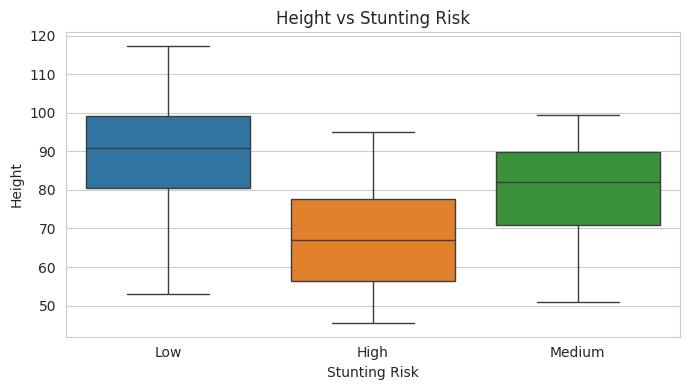

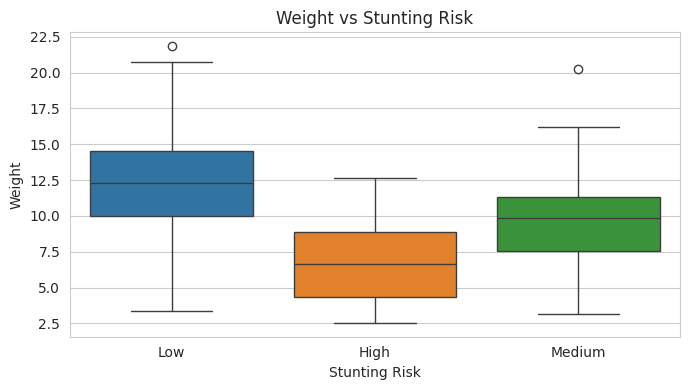

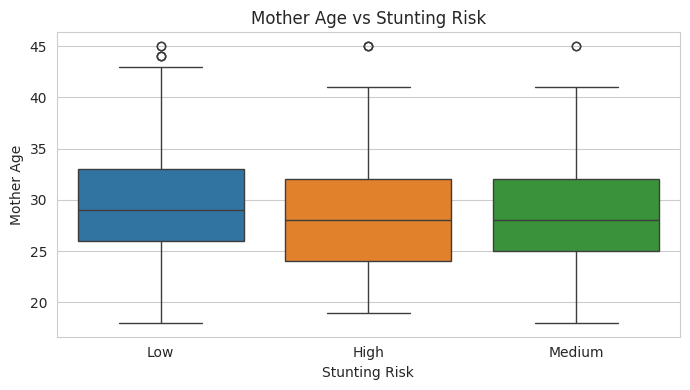

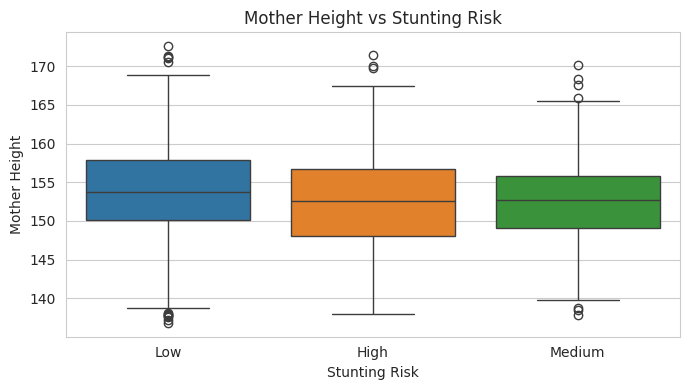

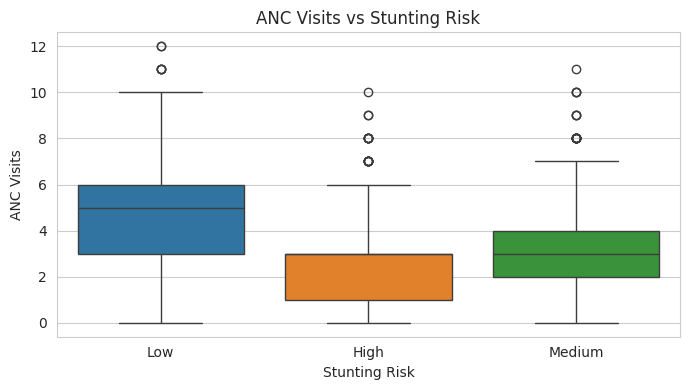

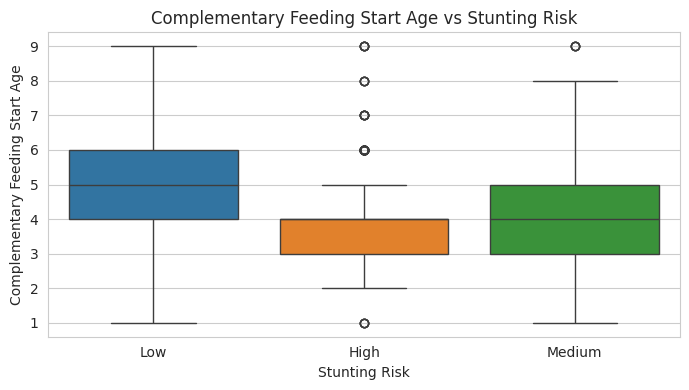

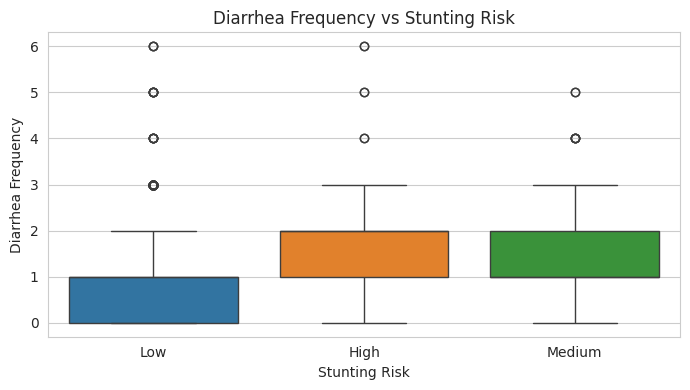

In [ ]:
for col in numeric_cols:

    if col == TARGET:
        continue

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=col,
        hue=TARGET,
        legend=False
    )

    plt.title(f"{col} vs {TARGET}")
    plt.tight_layout()
    plt.show()

In [ ]:
# Target encoding
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    df[TARGET].astype(str)
)

print("Target Mapping:")
print(dict(enumerate(label_encoder.classes_)))

# Separate input features
X = df.drop(columns=[TARGET]).copy()

# Remove identifier columns
id_cols = [
    col for col in X.columns
    if col.lower() in [
        "id", "patient_id", "record_id", "no"
    ]
]

X = X.drop(columns=id_cols, errors="ignore")

# Early-risk experiment
EARLY_RISK_MODE = True

if EARLY_RISK_MODE:

    leakage_terms = [
        "body length",
        "height-for-age",
        "height for age",
        "body weight"
    ]

    excluded_cols = [
        col for col in X.columns
        if any(term in col.lower() for term in leakage_terms)
    ]

    X = X.drop(columns=excluded_cols)

    print("Excluded current anthropometric features:", excluded_cols)

# Identify feature types
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

print("\nFinal Feature Shape:", X.shape)

Target Mapping:
{0: 'High', 1: 'Low', 2: 'Medium'}
Excluded current anthropometric features: []

Numerical Features: ['Child Age', 'Birth Length', 'Birth Weight', 'Height', 'Weight', 'Mother Age', 'Mother Height', 'ANC Visits', 'Complementary Feeding Start Age', 'Diarrhea Frequency']
Categorical Features: ['Gender', 'Mother Education', 'Exclusive Breastfeeding', 'Immunization', 'Drinking Water Source', 'Sanitation', 'Economic Level', 'Residence Type', 'Deworming Drug Consumption']

Final Feature Shape: (2523, 19)


In [ ]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1765,
    random_state=42,
    stratify=y_train_full
)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

Training Samples: 1765
Validation Samples: 379
Testing Samples: 379


In [ ]:
# Numerical preprocessing
num_imputer = SimpleImputer(strategy="median")

scaler = StandardScaler()

if len(numeric_features) > 0:

    X_train_num = scaler.fit_transform(
        num_imputer.fit_transform(
            X_train[numeric_features]
        )
    )

    X_val_num = scaler.transform(
        num_imputer.transform(
            X_val[numeric_features]
        )
    )

    X_test_num = scaler.transform(
        num_imputer.transform(
            X_test[numeric_features]
        )
    )

else:
    X_train_num = np.zeros((len(X_train), 0))
    X_val_num = np.zeros((len(X_val), 0))
    X_test_num = np.zeros((len(X_test), 0))


# Categorical preprocessing
if len(categorical_features) > 0:

    cat_imputer = SimpleImputer(
        strategy="most_frequent"
    )

    train_cat = cat_imputer.fit_transform(
        X_train[categorical_features]
    )

    val_cat = cat_imputer.transform(
        X_val[categorical_features]
    )

    test_cat = cat_imputer.transform(
        X_test[categorical_features]
    )

    cat_encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_train_cat = cat_encoder.fit_transform(
        train_cat
    ).astype(int) + 1

    X_val_cat = cat_encoder.transform(
        val_cat
    ).astype(int) + 1

    X_test_cat = cat_encoder.transform(
        test_cat
    ).astype(int) + 1

    category_sizes = [
        len(categories) + 1
        for categories in cat_encoder.categories_
    ]

else:

    X_train_cat = np.zeros((len(X_train), 0), dtype=int)
    X_val_cat = np.zeros((len(X_val), 0), dtype=int)
    X_test_cat = np.zeros((len(X_test), 0), dtype=int)

    category_sizes = []

# Convert to tensors
def make_tensor(data, dtype):
    return torch.tensor(data, dtype=dtype)

x_train_num = make_tensor(X_train_num, torch.float32)
x_val_num = make_tensor(X_val_num, torch.float32)
x_test_num = make_tensor(X_test_num, torch.float32)

x_train_cat = make_tensor(X_train_cat, torch.long)
x_val_cat = make_tensor(X_val_cat, torch.long)
x_test_cat = make_tensor(X_test_cat, torch.long)

y_train_t = make_tensor(y_train, torch.long)
y_val_t = make_tensor(y_val, torch.long)
y_test_t = make_tensor(y_test, torch.long)

num_features = x_train_num.shape[1]
num_classes = len(label_encoder.classes_)

print("Preprocessing completed!")
print("Number of classes:", num_classes)
print("Number of numerical features:", num_features)
print("Number of categorical features:", len(category_sizes))

Preprocessing completed!
Number of classes: 3
Number of numerical features: 10
Number of categorical features: 9


In [ ]:
class StuntingDeepModel(nn.Module):

    def __init__(
        self,
        model_type,
        num_features,
        category_sizes,
        num_classes,
        d_model=32
    ):
        super().__init__()

        self.model_type = model_type
        self.num_features = num_features
        self.n_cat = len(category_sizes)
        self.d_model = d_model

        # Categorical embeddings
        self.cat_embeddings = nn.ModuleList([
            nn.Embedding(size, d_model)
            for size in category_sizes
        ])

        if model_type == "FT-Transformer":

            self.num_weight = nn.Parameter(
                torch.randn(num_features, d_model) * 0.02
            )

            self.num_bias = nn.Parameter(
                torch.zeros(num_features, d_model)
            )

            self.cls_token = nn.Parameter(
                torch.randn(1, 1, d_model) * 0.02
            )

            self.encoder = nn.TransformerEncoder(
                nn.TransformerEncoderLayer(
                    d_model=d_model,
                    nhead=4,
                    dim_feedforward=64,
                    dropout=0.2,
                    batch_first=True,
                    activation="gelu"
                ),
                num_layers=2
            )

            self.head = nn.Linear(d_model, num_classes)

        elif model_type == "TabTransformer":

            self.encoder = nn.TransformerEncoder(
                nn.TransformerEncoderLayer(
                    d_model=d_model,
                    nhead=4,
                    dim_feedforward=64,
                    dropout=0.2,
                    batch_first=True,
                    activation="gelu"
                ),
                num_layers=2
            )

            self.head = nn.Sequential(
                nn.Linear(num_features + d_model, 64),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(64, num_classes)
            )

        elif model_type == "MLP":

            self.head = nn.Sequential(
                nn.Linear(
                    num_features + self.n_cat * d_model,
                    128
                ),
                nn.ReLU(),
                nn.Dropout(0.3),
                nn.Linear(128, 64),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(64, num_classes)
            )

    def forward(self, x_num, x_cat):

        cat_tokens = []

        for i, embedding in enumerate(self.cat_embeddings):

            cat_tokens.append(
                embedding(x_cat[:, i]).unsqueeze(1)
            )

        if len(cat_tokens) > 0:

            cat_tokens = torch.cat(
                cat_tokens, dim=1
            )

        else:

            cat_tokens = torch.empty(
                x_num.size(0),
                0,
                self.d_model,
                device=x_num.device
            )

        # FT-Transformer
        if self.model_type == "FT-Transformer":

            num_tokens = (
                x_num.unsqueeze(-1) * self.num_weight
                + self.num_bias
            )

            tokens = torch.cat([
                self.cls_token.expand(x_num.size(0), -1, -1),
                num_tokens,
                cat_tokens
            ], dim=1)

            encoded = self.encoder(tokens)

            return self.head(encoded[:, 0, :])

        # TabTransformer
        elif self.model_type == "TabTransformer":

            if self.n_cat > 0:

                encoded_cat = self.encoder(cat_tokens)

                cat_features = encoded_cat.mean(dim=1)

            else:

                cat_features = torch.zeros(
                    x_num.size(0),
                    self.d_model,
                    device=x_num.device
                )

            combined = torch.cat([
                x_num,
                cat_features
            ], dim=1)

            return self.head(combined)

        # MLP
        else:

            combined = torch.cat([
                x_num,
                cat_tokens.flatten(start_dim=1)
            ], dim=1)

            return self.head(combined)

In [ ]:
batch_size = 64

train_loader = DataLoader(
    TensorDataset(
        x_train_num,
        x_train_cat,
        y_train_t
    ),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        x_val_num,
        x_val_cat,
        y_val_t
    ),
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(
        x_test_num,
        x_test_cat,
        y_test_t
    ),
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [ ]:
def calculate_macro_f1(model, loader):

    model.eval()

    actual = []
    predicted = []

    with torch.no_grad():

        for xn, xc, yb in loader:

            outputs = model(
                xn.to(device),
                xc.to(device)
            )

            pred = outputs.argmax(dim=1)

            actual.extend(yb.numpy())
            predicted.extend(pred.cpu().numpy())

    return f1_score(
        actual,
        predicted,
        average="macro",
        zero_division=0
    )


def train_model(model, epochs=50, patience=8):

    model = model.to(device)

    class_counts = np.bincount(
        y_train,
        minlength=num_classes
    )

    class_weights = len(y_train) / (
        num_classes * np.maximum(class_counts, 1)
    )

    weights = torch.tensor(
        class_weights,
        dtype=torch.float32
    ).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=weights
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    best_f1 = -1
    best_state = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = {
        "loss": [],
        "val_f1": []
    }

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for xn, xc, yb in train_loader:

            xn = xn.to(device)
            xc = xc.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            outputs = model(xn, xc)

            loss = criterion(outputs, yb)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        val_f1 = calculate_macro_f1(
            model,
            val_loader
        )

        history["loss"].append(avg_loss)
        history["val_f1"].append(val_f1)

        if val_f1 > best_f1:

            best_f1 = val_f1

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 5 == 0:

            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Loss: {avg_loss:.4f} | "
                f"Validation Macro F1: {val_f1:.4f}"
            )

        if patience_counter >= patience:
            print("Early stopping activated.")
            break

    model.load_state_dict(best_state)

    return model, history, best_f1

In [ ]:

import copy
model_names = [
    "TabTransformer",
    "FT-Transformer",
    "MLP"
]

trained_models = {}
histories = {}
validation_scores = {}

for name in model_names:

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    model = StuntingDeepModel(
        model_type=name,
        num_features=num_features,
        category_sizes=category_sizes,
        num_classes=num_classes,
        d_model=32
    )

    model, history, best_val_f1 = train_model(
        model,
        epochs=50,
        patience=8
    )

    trained_models[name] = model
    histories[name] = history
    validation_scores[name] = best_val_f1

    print(
        f"{name} Best Validation Macro F1: "
        f"{best_val_f1:.4f}"
    )

print("\nAll three models trained successfully!")


Training: TabTransformer
Epoch 5/50 | Loss: 0.7592 | Validation Macro F1: 0.5975
Epoch 10/50 | Loss: 0.7043 | Validation Macro F1: 0.6410
Epoch 15/50 | Loss: 0.6580 | Validation Macro F1: 0.6613
Epoch 20/50 | Loss: 0.6096 | Validation Macro F1: 0.6932
Epoch 25/50 | Loss: 0.5476 | Validation Macro F1: 0.7106
Epoch 30/50 | Loss: 0.5044 | Validation Macro F1: 0.7281
Epoch 35/50 | Loss: 0.4605 | Validation Macro F1: 0.7469
Epoch 40/50 | Loss: 0.4274 | Validation Macro F1: 0.7623
Epoch 45/50 | Loss: 0.4122 | Validation Macro F1: 0.7751
Epoch 50/50 | Loss: 0.3986 | Validation Macro F1: 0.7746
TabTransformer Best Validation Macro F1: 0.7834

Training: FT-Transformer
Epoch 5/50 | Loss: 0.8178 | Validation Macro F1: 0.6031
Epoch 10/50 | Loss: 0.7439 | Validation Macro F1: 0.6540
Epoch 15/50 | Loss: 0.6853 | Validation Macro F1: 0.6666
Epoch 20/50 | Loss: 0.6361 | Validation Macro F1: 0.6418
Epoch 25/50 | Loss: 0.5835 | Validation Macro F1: 0.7569
Epoch 30/50 | Loss: 0.5521 | Validation Macro F

In [ ]:
def evaluate_model(model, loader):

    model.eval()

    actual = []
    predicted = []
    probabilities = []

    with torch.no_grad():

        for xn, xc, yb in loader:

            outputs = model(
                xn.to(device),
                xc.to(device)
            )

            probs = torch.softmax(outputs, dim=1)

            predictions = outputs.argmax(dim=1)

            actual.extend(yb.numpy())
            predicted.extend(
                predictions.cpu().numpy()
            )

            probabilities.extend(
                probs.cpu().numpy()
            )

    actual = np.array(actual)
    predicted = np.array(predicted)
    probabilities = np.array(probabilities)

    if num_classes == 2:

        auc = roc_auc_score(
            actual,
            probabilities[:, 1]
        )

    else:

        auc = roc_auc_score(
            actual,
            probabilities,
            multi_class="ovr",
            average="weighted"
        )

    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted,
            average="weighted",
            zero_division=0
        ),
        "Macro F1": f1_score(
            actual, predicted,
            average="macro",
            zero_division=0
        ),
        "ROC-AUC": auc,
        "Predictions": predicted,
        "Probabilities": probabilities,
        "Actual": actual
    }


results = []

evaluation_outputs = {}

for name, model in trained_models.items():

    print("Evaluating:", name)

    output = evaluate_model(
        model,
        test_loader
    )

    evaluation_outputs[name] = output

    results.append({
        "Model": name,
        "Validation Macro F1": validation_scores[name],
        "Accuracy": output["Accuracy"],
        "Precision": output["Precision"],
        "Recall": output["Recall"],
        "Macro F1": output["Macro F1"],
        "ROC-AUC": output["ROC-AUC"]
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "Validation Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Validation Macro F1": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

Evaluating: TabTransformer
Evaluating: FT-Transformer
Evaluating: MLP


,Model,Validation Macro F1,Accuracy,Precision,Recall,Macro F1,ROC-AUC
0,FT-Transformer,0.8589,0.9024,0.9118,0.9024,0.8649,0.9829
1,TabTransformer,0.7834,0.7995,0.8208,0.7995,0.7375,0.9363
2,MLP,0.6323,0.6544,0.7390,0.6544,0.6029,0.8486


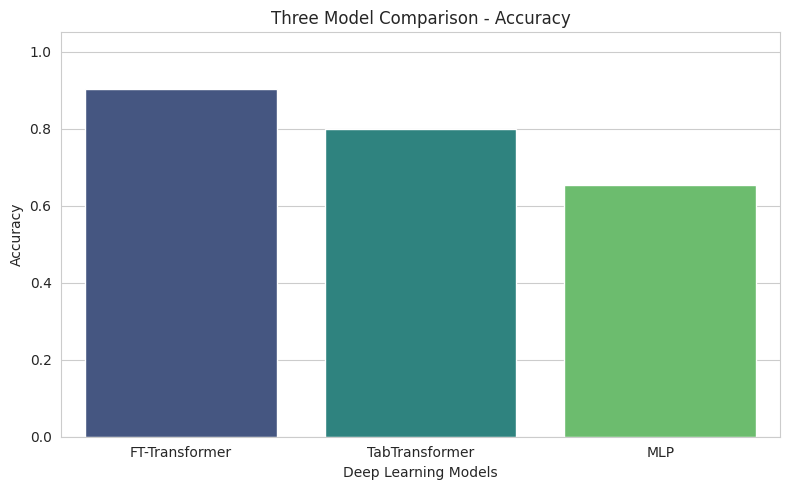

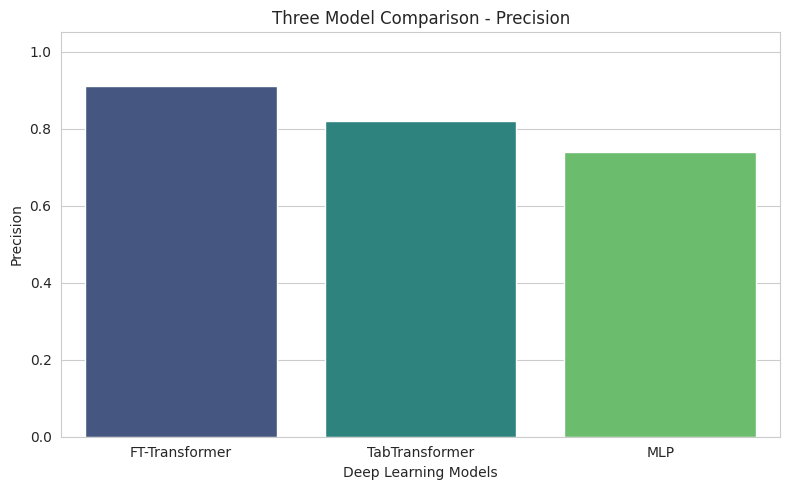

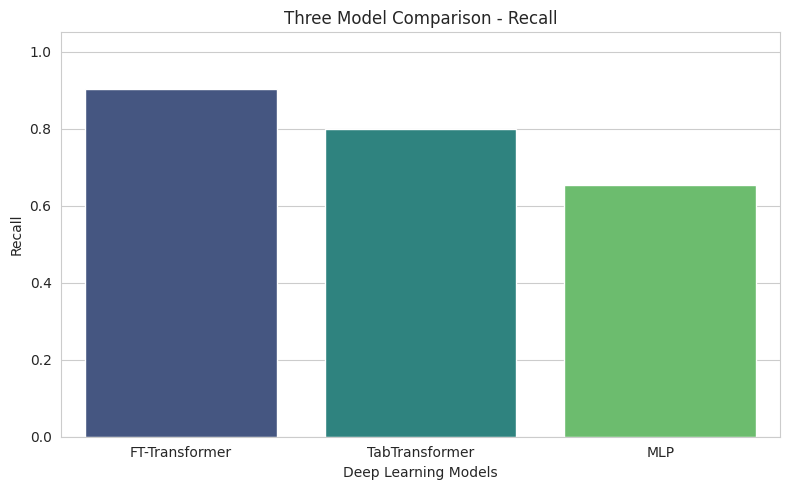

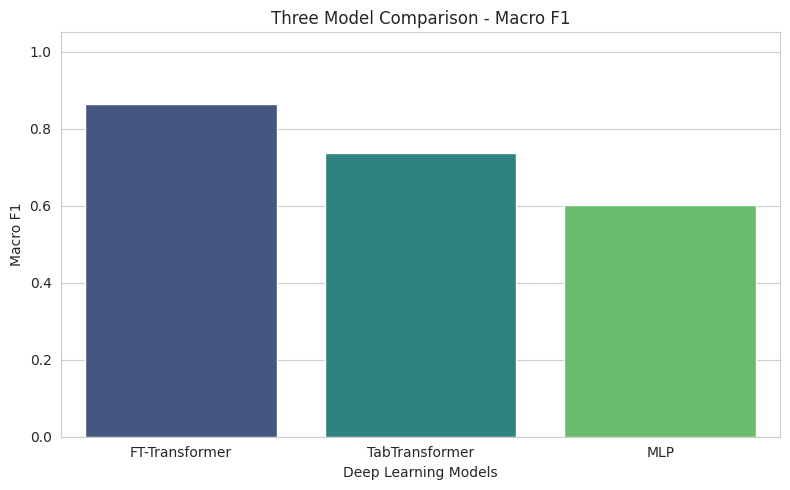

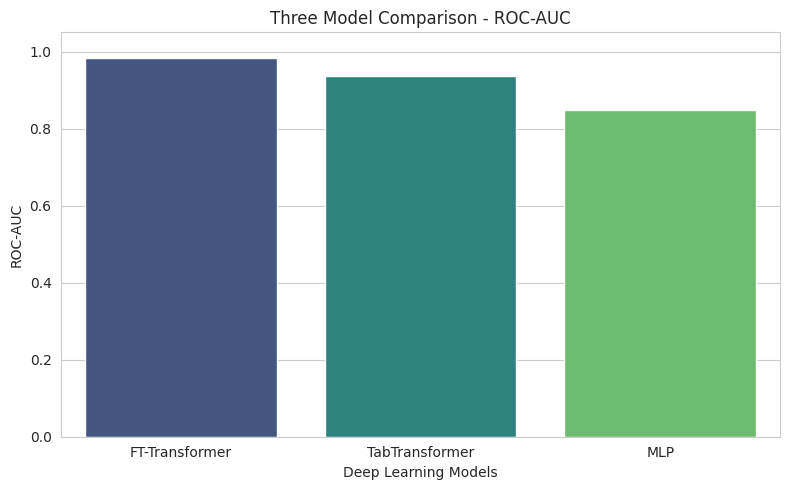

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        hue="Model",
        palette="viridis",
        legend=False
    )

    plt.title(f"Three Model Comparison - {metric}")
    plt.ylim(0, 1.05)
    plt.xlabel("Deep Learning Models")
    plt.ylabel(metric)

    plt.tight_layout()
    plt.show()

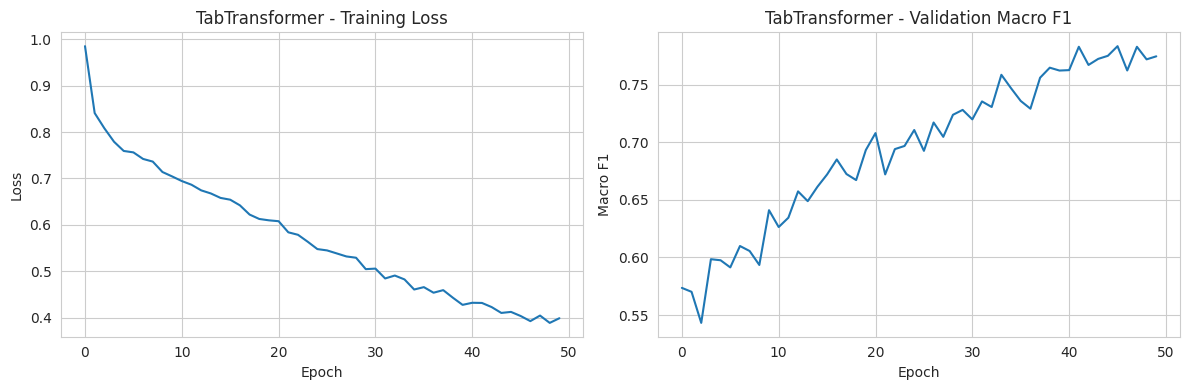

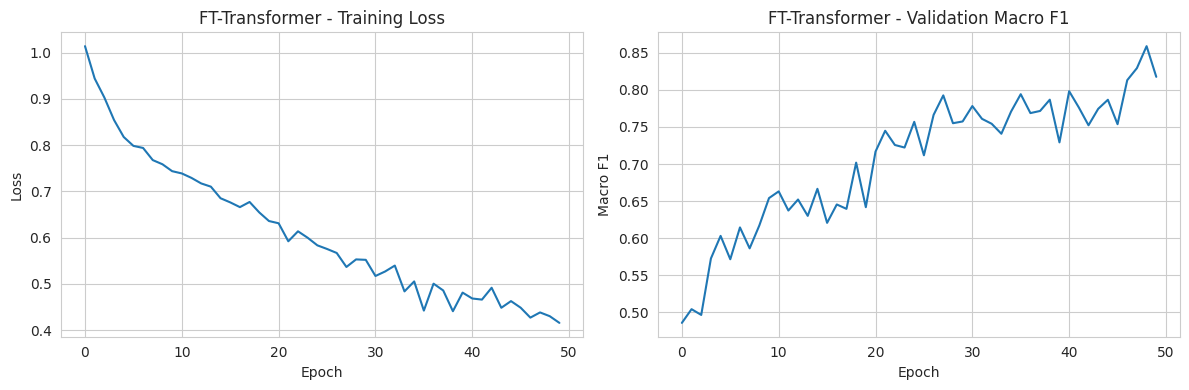

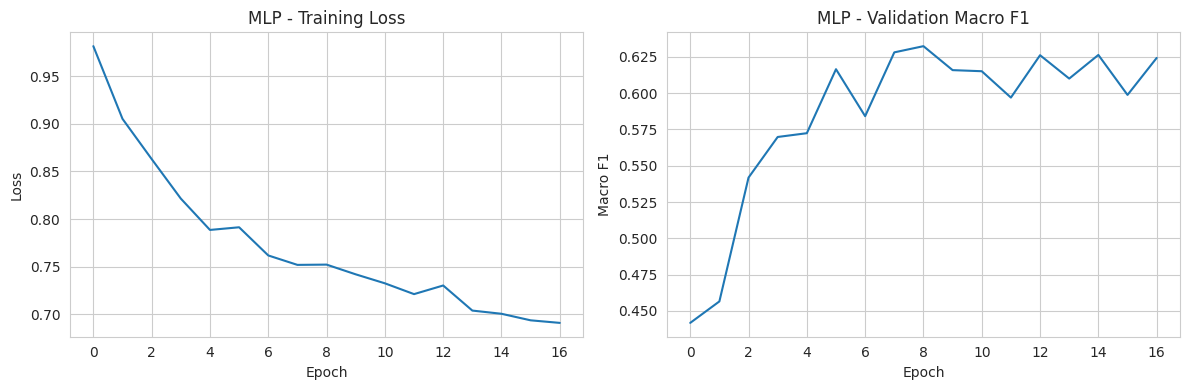

In [ ]:
import copy

for name, history in histories.items():

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["loss"])
    axes[0].set_title(f"{name} - Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")

    axes[1].plot(history["val_f1"])
    axes[1].set_title(f"{name} - Validation Macro F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Macro F1")

    plt.tight_layout()
    plt.show()

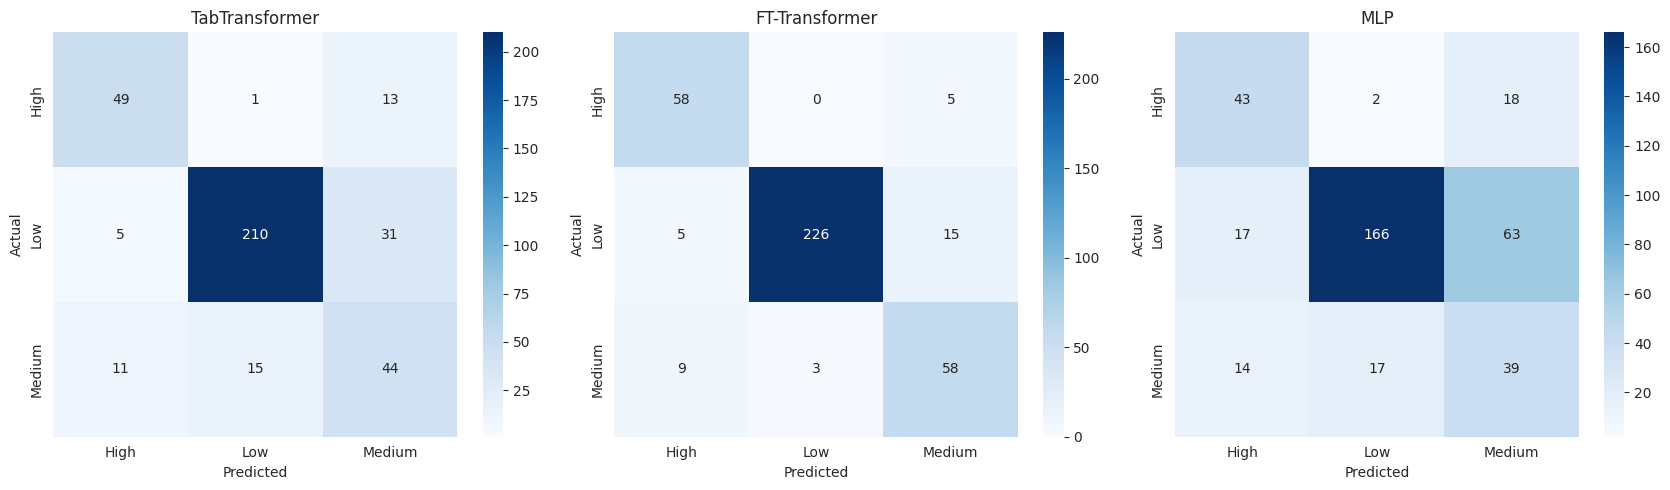

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, name in zip(axes, model_names):

    predictions = evaluation_outputs[name]["Predictions"]

    cm = confusion_matrix(
        y_test,
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("=" * 50)
print("BEST MODEL:", best_model_name)
print("=" * 50)

best_output = evaluation_outputs[best_model_name]

print("\nTest Performance")

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "ROC-AUC"
]:

    print(
        metric,
        ":",
        round(results_df.iloc[0][metric], 4)
    )

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_output["Predictions"],
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_.astype(str),
        zero_division=0
    )
)

BEST MODEL: FT-Transformer

Test Performance
Accuracy : 0.9024
Precision : 0.9118
Recall : 0.9024
Macro F1 : 0.8649
ROC-AUC : 0.9829

Classification Report:
              precision    recall  f1-score   support

        High       0.81      0.92      0.86        63
         Low       0.99      0.92      0.95       246
      Medium       0.74      0.83      0.78        70

    accuracy                           0.90       379
   macro avg       0.85      0.89      0.86       379
weighted avg       0.91      0.90      0.91       379



In [ ]:
torch.save(
    best_model.state_dict(),
    "/kaggle/working/best_stunting_model.pth"
)

joblib.dump(
    {
        "num_imputer": num_imputer,
        "scaler": scaler,
        "cat_imputer": cat_imputer if len(categorical_features) > 0 else None,
        "cat_encoder": cat_encoder if len(categorical_features) > 0 else None,
        "label_encoder": label_encoder,
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "category_sizes": category_sizes,
        "model_name": best_model_name,
        "num_features": num_features,
        "num_classes": num_classes,
        "d_model": 32
    },
    "/kaggle/working/stunting_preprocessing.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [ ]:
print("=" * 60)
print("STUNTING PREDICTION - RESEARCH SUMMARY")
print("=" * 60)

print("Dataset:", "Stunting Toddler Dataset")
print("Total Samples:", len(df))
print("Input Features:", X.shape[1])
print("Number of Classes:", num_classes)

print("\nModels Compared:")
for name in model_names:
    print("-", name)

print("\nModel Comparison:")
display(results_df)

print("\nBest Model:", best_model_name)

print(
    "\nBest Test Macro F1:",
    round(best_output["Macro F1"], 4)
)

print("\nResearch Conclusion:")
print(
    f"{best_model_name} achieved the highest validation "
    "Macro F1 among the three evaluated deep learning models."
)

print("=" * 60)

STUNTING PREDICTION - RESEARCH SUMMARY
Dataset: Stunting Toddler Dataset
Total Samples: 2523
Input Features: 19
Number of Classes: 3

Models Compared:
- TabTransformer
- FT-Transformer
- MLP

Model Comparison:


,Model,Validation Macro F1,Accuracy,Precision,Recall,Macro F1,ROC-AUC
0,FT-Transformer,0.858864,0.902375,0.911817,0.902375,0.864874,0.982886
1,TabTransformer,0.783433,0.799472,0.820782,0.799472,0.737473,0.936301
2,MLP,0.632307,0.654354,0.739032,0.654354,0.602855,0.848587



Best Model: FT-Transformer

Best Test Macro F1: 0.8649

Research Conclusion:
FT-Transformer achieved the highest validation Macro F1 among the three evaluated deep learning models.
